# Exploratory Data Analysis for Machine Learning — Final Project
## Student Performance Dataset

**Goal:** explore student achievement data, document data quality, engineer features, formulate hypotheses, and perform statistically valid hypothesis tests.

**Dataset source:** UCI Machine Learning Repository — Student Performance  
https://archive.ics.uci.edu/dataset/320/student+performance

**Important:** This notebook retrieves the public dataset from UCI at runtime. Run all cells in order to generate actual dataset statistics, charts, and p-values. Do not report results until the notebook has completed successfully.

## 1. Dataset Summary

The Student Performance dataset describes secondary-school students in Portugal. It contains student grades and demographic, social, family, and school-related attributes. We use the Mathematics dataset (`student-mat.csv`) for a focused analysis. The final grade (`G3`) is a potential target for a later regression model.

The dataset is observational, so relationships should not automatically be interpreted as causal. The source notes that `G1` and `G2` are strongly associated with `G3`; these variables may be useful for prediction but can make a model less useful when early-period grades are not available.

In [8]:

import io
import zipfile
import urllib.request
import pandas as pd
from IPython.display import display

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

# Download ZIP utama
with urllib.request.urlopen(url, timeout=30) as response:
    raw = response.read()

outer_zip = zipfile.ZipFile(io.BytesIO(raw))

# Buka ZIP yang ada di dalam ZIP utama
with outer_zip.open("student.zip") as nested_file:
    inner_bytes = nested_file.read()

inner_zip = zipfile.ZipFile(io.BytesIO(inner_bytes))

print("Isi ZIP bagian dalam:")
print(inner_zip.namelist())

# Cari dataset matematika
matches = [
    name for name in inner_zip.namelist()
    if name.lower().endswith("student-mat.csv")
]

if matches:
    df = pd.read_csv(inner_zip.open(matches[0]), sep=";")
    print("\nDataset berhasil dimuat!")
    print("Jumlah baris dan kolom:", df.shape)
    display(df.head())
else:
    print("\nCSV belum ditemukan. Kirim hasil daftar file ZIP bagian dalam.")


Isi ZIP bagian dalam:
['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']

Dataset berhasil dimuat!
Jumlah baris dan kolom: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [9]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names and dtypes:")
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values}))
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Rows: 395
Columns: 33

Column names and dtypes:


,column,dtype
0,school,object
1,sex,object
2,age,int64
3,address,object
4,famsize,object
5,Pstatus,object
6,Medu,int64
7,Fedu,int64
8,Mjob,object
9,Fjob,object



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data Exploration Plan

1. Verify dataset dimensions, data types, and variable definitions.
2. Check missing values, duplicate rows, and invalid or unusual values.
3. Explore distributions of final grades, study time, absences, and previous grades.
4. Compare final grades across study-time and school-support groups.
5. Examine numeric relationships and correlations, noting that correlation does not imply causation.
6. Formulate at least three testable hypotheses and conduct appropriate significance tests.
7. Prepare a clean modelling table, encode categorical variables, and scale numeric predictors where useful.
8. Summarize key insights and limitations.

## 3. Data Quality Checks

In [10]:
missing = df.isna().sum().sort_values(ascending=False)
print("Missing values per column:")
display(missing.to_frame("missing_count"))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Data types:")
display(df.dtypes.astype(str).to_frame("dtype"))
print("Numeric summary:")
display(df.select_dtypes(include=np.number).describe().T)

Missing values per column:


,missing_count
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Duplicate rows: 0
Data types:


,dtype
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


## 4. Exploratory Data Analysis

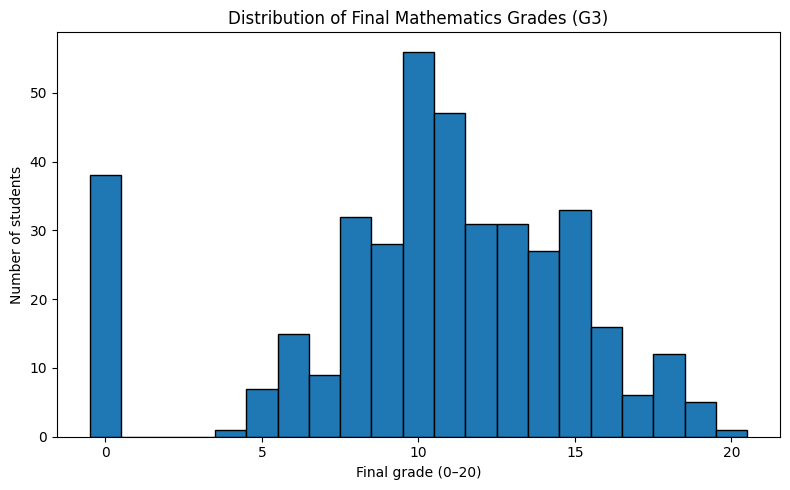

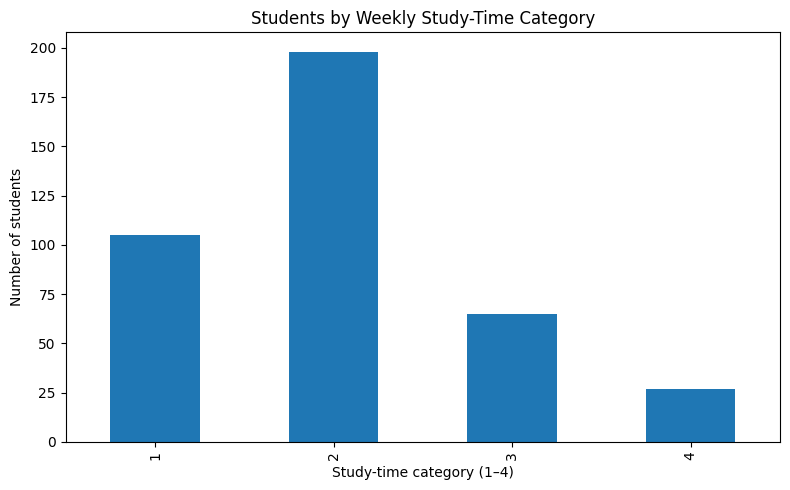

/tmp/ipykernel_1888/1071811837.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df.loc[df["studytime"] == k, "G3"] for k in sorted(df["studytime"].unique())],


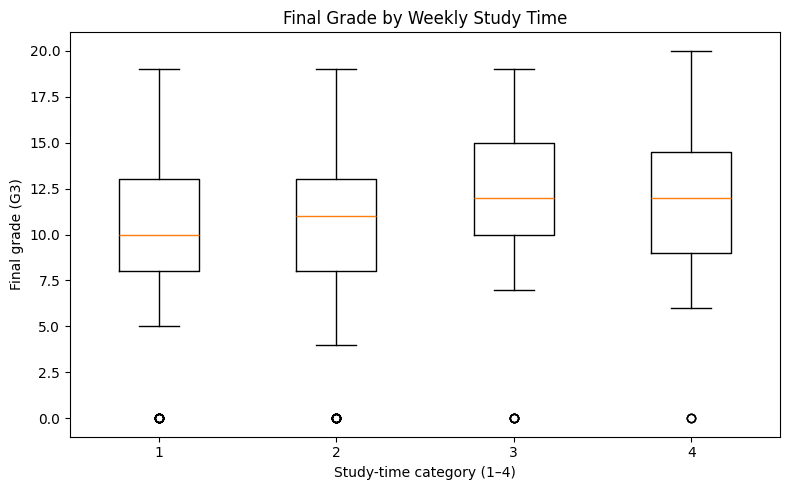

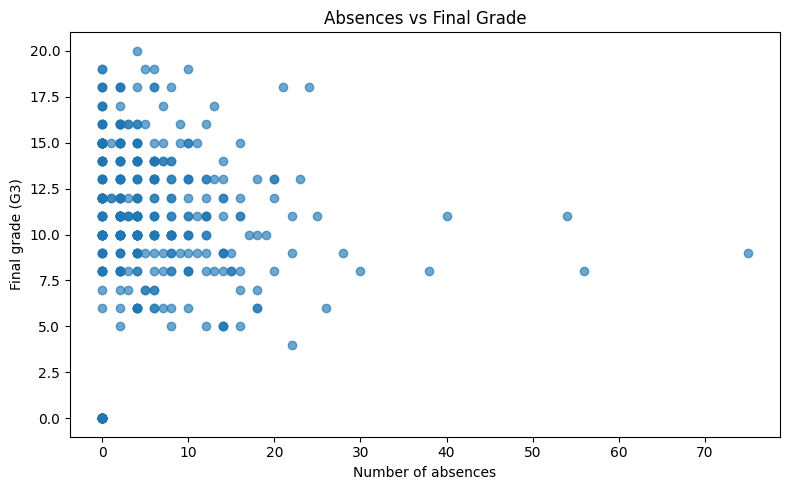

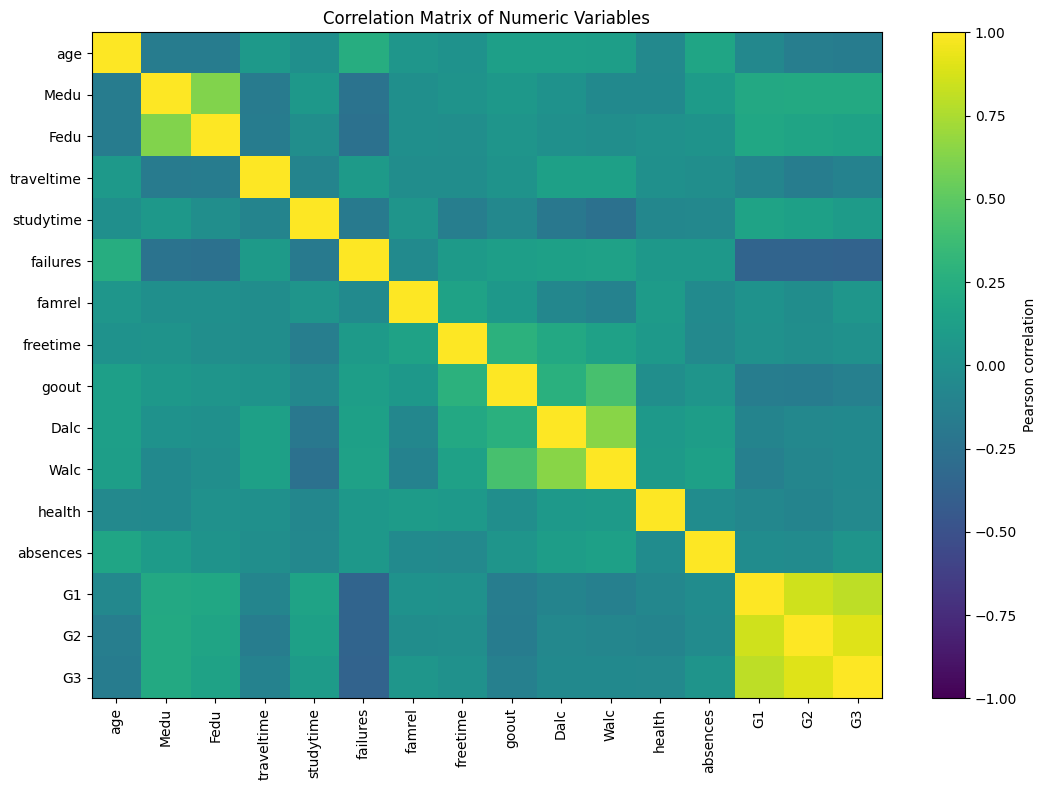

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["G3"], bins=np.arange(-0.5, 21.5, 1), edgecolor="black")
ax.set(title="Distribution of Final Mathematics Grades (G3)", xlabel="Final grade (0–20)", ylabel="Number of students")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
df["studytime"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set(title="Students by Weekly Study-Time Category", xlabel="Study-time category (1–4)", ylabel="Number of students")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([df.loc[df["studytime"] == k, "G3"] for k in sorted(df["studytime"].unique())],
           labels=sorted(df["studytime"].unique()))
ax.set(title="Final Grade by Weekly Study Time", xlabel="Study-time category (1–4)", ylabel="Final grade (G3)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["absences"], df["G3"], alpha=0.65)
ax.set(title="Absences vs Final Grade", xlabel="Number of absences", ylabel="Final grade (G3)")
plt.tight_layout()
plt.show()

numeric = df.select_dtypes(include=np.number)
corr = numeric.corr()
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns)
ax.set_title("Correlation Matrix of Numeric Variables")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

## 5. Key Findings & Insights

The next cell generates dataset-specific values for five findings. Use these values to write the final narrative after running the notebook; do not assume the direction or magnitude in advance.

- Final-grade distribution and its centre/spread.
- Differences in final grades by study-time category.
- Association between absences and final grades.
- Correlation of earlier-period grades (`G1`, `G2`) with final grade (`G3`).
- Data quality: missing values, duplicates, and possible outliers.

In [12]:
print("Finding 1 — Final grade summary")
display(df["G3"].describe().to_frame("G3"))

print("Finding 2 — Grade summary by study-time category")
display(df.groupby("studytime")["G3"].agg(["count", "mean", "median", "std"]).round(3))

print("Finding 3 — Absences and final grade")
print("Pearson r =", round(df["absences"].corr(df["G3"]), 4))

print("Finding 4 — Earlier grades and final grade")
display(df[["G1", "G2", "G3"]].corr().round(3))

print("Finding 5 — Quality overview")
print({"rows": len(df), "columns": df.shape[1],
       "missing_cells": int(df.isna().sum().sum()),
       "duplicate_rows": int(df.duplicated().sum())})

Finding 1 — Final grade summary


,G3
count,395.000000
mean,10.415190
std,4.581443
min,0.000000
25%,8.000000
50%,11.000000
75%,14.000000
max,20.000000


Finding 2 — Grade summary by study-time category


,count,mean,median,std
studytime,,,,
1,105,10.048,10.0,4.956
2,198,10.172,11.0,4.218
3,65,11.400,12.0,4.640
4,27,11.259,12.0,5.281


Finding 3 — Absences and final grade
Pearson r = 0.0342
Finding 4 — Earlier grades and final grade


,G1,G2,G3
G1,1.000,0.852,0.801
G2,0.852,1.000,0.905
G3,0.801,0.905,1.000


Finding 5 — Quality overview
{'rows': 395, 'columns': 33, 'missing_cells': 0, 'duplicate_rows': 0}


## 6. Hypothesis Formulation

We predefine three hypotheses. Tests are two-sided unless stated otherwise, with significance level α = 0.05.

**H1 — Study time and final grade**
- H₀: Mean final grade is equal for students in the lowest study-time category (1) and students in categories 2–4.
- H₁: Mean final grade differs between these groups.
- Test: Welch independent-samples t-test (does not assume equal variances).

**H2 — School support and final grade**
- H₀: Mean final grade is equal for students receiving extra school support and those not receiving it.
- H₁: Mean final grade differs between the two groups.
- Test: Welch independent-samples t-test.

**H3 — Absences and final grade**
- H₀: Population Pearson correlation between absences and final grade is zero.
- H₁: Population Pearson correlation is not zero.
- Test: Pearson correlation significance test. Interpret cautiously if assumptions (linearity, outliers, approximate bivariate normality) are questionable; a Spearman sensitivity analysis is also included.

In [13]:
def welch_test(data, group_col, group_a, group_b, outcome="G3"):
    a = data.loc[data[group_col] == group_a, outcome].dropna()
    b = data.loc[data[group_col] == group_b, outcome].dropna()
    t_stat, p_value = stats.ttest_ind(a, b, equal_var=False, alternative="two-sided")
    return {
        "group_a": str(group_a), "n_a": len(a), "mean_a": a.mean(),
        "group_b": str(group_b), "n_b": len(b), "mean_b": b.mean(),
        "mean_difference_a_minus_b": a.mean() - b.mean(),
        "t_statistic": t_stat, "p_value": p_value,
        "reject_H0_at_0.05": bool(p_value < ALPHA)
    }

# H1: study time category 1 vs categories 2–4
study_group = df["studytime"].apply(lambda x: "Lowest (1)" if x == 1 else "Higher (2–4)")
h1 = welch_test(df.assign(study_group=study_group), "study_group", "Lowest (1)", "Higher (2–4)")
print("H1 — Study time and final grade")
display(pd.DataFrame([h1]))

# H2: school support yes vs no
h2 = welch_test(df, "schoolsup", "yes", "no")
print("H2 — School support and final grade")
display(pd.DataFrame([h2]))

# H3: absences and final grade
valid = df[["absences", "G3"]].dropna()
r, p_pearson = stats.pearsonr(valid["absences"], valid["G3"])
rho, p_spearman = stats.spearmanr(valid["absences"], valid["G3"])
h3 = pd.DataFrame([{
    "pearson_r": r, "pearson_p_value": p_pearson,
    "spearman_rho": rho, "spearman_p_value": p_spearman,
    "reject_H0_Pearson_at_0.05": bool(p_pearson < ALPHA),
    "reject_H0_Spearman_at_0.05": bool(p_spearman < ALPHA)
}])
print("H3 — Absences and final grade")
display(h3)

H1 — Study time and final grade


,group_a,n_a,mean_a,group_b,n_b,mean_b,mean_difference_a_minus_b,t_statistic,p_value,reject_H0_at_0.05
0,Lowest (1),105,10.047619,Higher (2–4),290,10.548276,-0.500657,-0.911169,0.363511,False


H2 — School support and final grade


,group_a,n_a,mean_a,group_b,n_b,mean_b,mean_difference_a_minus_b,t_statistic,p_value,reject_H0_at_0.05
0,yes,51,9.431373,no,344,10.561047,-1.129674,-2.370455,0.019742,True


H3 — Absences and final grade


,pearson_r,pearson_p_value,spearman_rho,spearman_p_value,reject_H0_Pearson_at_0.05,reject_H0_Spearman_at_0.05
0,0.034247,0.497332,0.017731,0.725363,False,False


## 7. Significance Analysis and Interpretation

For each test, compare the p-value with α = 0.05:
- If p < 0.05, reject H₀; the data provide evidence of a statistically significant difference/association.
- If p ≥ 0.05, fail to reject H₀; the data do not provide sufficient evidence of a difference/association.

A p-value is not the probability that H₀ is true. Statistical significance also does not establish practical importance or causation. Report group means, sample sizes, effect direction, and p-values together. Because three hypotheses are tested, consider multiple-testing adjustment when making a family-wide claim.

In [14]:
# Optional family-wise adjustment using the Holm method for the three primary p-values
pvals = np.array([h1["p_value"], h2["p_value"], p_pearson], dtype=float)
labels = ["H1: study time", "H2: school support", "H3: absences correlation"]
order = np.argsort(pvals)
adjusted = np.empty_like(pvals)
running_max = 0.0
m = len(pvals)
for rank, idx in enumerate(order):
    value = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, value)
    adjusted[idx] = running_max
holm = pd.DataFrame({"hypothesis": labels, "raw_p_value": pvals,
                     "holm_adjusted_p_value": adjusted,
                     "reject_after_holm_at_0.05": adjusted < ALPHA})
display(holm)

,hypothesis,raw_p_value,holm_adjusted_p_value,reject_after_holm_at_0.05
0,H1: study time,0.363511,0.727023,False
1,H2: school support,0.019742,0.059225,False
2,H3: absences correlation,0.497332,0.727023,False


## 8. Data Cleaning & Feature Engineering

This section creates a reproducible preparation pipeline. Missing numeric values are imputed with the median and categorical values with the most frequent category. Categorical variables are one-hot encoded and numeric variables standardized. Preprocessing is fitted only on the training split to avoid data leakage.

For a future model predicting `G3`, `G1` and `G2` are excluded in the baseline feature set to demonstrate a more realistic prediction scenario where earlier grades may not be available. They can be included in a separate benchmark if the use case permits.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

model_df = df.copy()
target = "G3"
# Exclude target and earlier grades to avoid relying on highly predictive prior-period grades.
X = model_df.drop(columns=[target, "G1", "G2"])
y = model_df[target]

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, num_cols),
    ("categorical", categorical_pipe, cat_cols)
])

X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

print("Training rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])
print("Numeric features:", len(num_cols), "| Categorical features:", len(cat_cols))
print("Transformed training shape:", X_train_ready.shape)
print("Transformed test shape:", X_test_ready.shape)

Training rows: 316 | Test rows: 79
Numeric features: 13 | Categorical features: 17
Transformed training shape: (316, 56)
Transformed test shape: (79, 56)


### Outlier review

Outliers should be investigated rather than removed automatically: unusually high absences or low grades may be genuine observations. The IQR rule below flags candidate outliers for review; it does not delete them.

In [16]:
def iqr_outlier_summary(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {"variable": series.name, "lower_fence": low, "upper_fence": high,
            "candidate_outliers": int(((series < low) | (series > high)).sum())}

display(pd.DataFrame([
    iqr_outlier_summary(df["absences"]),
    iqr_outlier_summary(df["G3"])
]))

,variable,lower_fence,upper_fence,candidate_outliers
0,absences,-12.0,20.0,15
1,G3,-1.0,23.0,0


## Conclusion & Next Steps

After running the notebook, summarize the actual EDA and hypothesis-test outputs here. Include the strongest observed patterns, data quality decisions, and limitations. Next steps are to compare at least two regression models, evaluate them with MAE/RMSE/R², inspect residuals, and explain whether the available predictors support the intended use case.

**Limitations:** The dataset comes from two Portuguese schools and may not generalize to other education systems. It is observational, so results indicate association rather than causation. Some variables are self-reported categories, and grade distributions may be specific to the study context.